# Análise Exploratória — Dataset Olist
Tech Challenge Fase 1 — Agentic AI

## 1. Setup e carregamento dos dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (9, 5)

DATA_DIR = "../dados"

customers = pd.read_csv(f"{DATA_DIR}/olist_customers_dataset.csv")
orders = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
])
order_items = pd.read_csv(f"{DATA_DIR}/olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
payments = pd.read_csv(f"{DATA_DIR}/olist_order_payments_dataset.csv")
reviews = pd.read_csv(f"{DATA_DIR}/olist_order_reviews_dataset.csv", parse_dates=["review_creation_date", "review_answer_timestamp"])
products = pd.read_csv(f"{DATA_DIR}/olist_products_dataset.csv")
sellers = pd.read_csv(f"{DATA_DIR}/olist_sellers_dataset.csv")
category_translation = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")
geolocation = pd.read_csv(f"{DATA_DIR}/olist_geolocation_dataset.csv")

datasets = {
    "customers": customers, "orders": orders, "order_items": order_items,
    "payments": payments, "reviews": reviews, "products": products,
    "sellers": sellers, "category_translation": category_translation,
    "geolocation": geolocation,
}
for name, df in datasets.items():
    print(f"{name:22s} {df.shape[0]:>9,} linhas  x  {df.shape[1]:>2} colunas")

customers                 99,441 linhas  x   5 colunas
orders                    99,441 linhas  x   8 colunas
order_items              112,650 linhas  x   7 colunas
payments                 103,886 linhas  x   5 colunas
reviews                   99,224 linhas  x   7 colunas
products                  32,951 linhas  x   9 colunas
sellers                    3,095 linhas  x   4 colunas
category_translation          71 linhas  x   2 colunas
geolocation            1,000,163 linhas  x   5 colunas


## 2. Visão geral do período e status dos pedidos

In [2]:
print("Período coberto:", orders["order_purchase_timestamp"].min(), "a", orders["order_purchase_timestamp"].max())
print("Total de pedidos:", len(orders))
print()
status_counts = orders["order_status"].value_counts()
status_pct = (status_counts / len(orders) * 100).round(2)
pd.DataFrame({"pedidos": status_counts, "%": status_pct})

Período coberto: 2016-09-04 21:15:19 a 2018-10-17 17:30:18
Total de pedidos: 99441



,pedidos,%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


In [3]:
print(customers.columns)
print(orders.columns)
print(order_items.columns)
print(payments.columns)
print(reviews.columns)
print(products.columns)
print(sellers.columns)
print(category_translation.columns)
print(geolocation.columns)

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state'], dtype='str')
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')
Index(['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value'], dtype='str')
Index(['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value'], dtype='str')
Index(['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='str')
Index(['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty',
       'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')
Index(['sel

## 3. Tabela consolidada (item de pedido + produto + cliente + vendedor)

In [4]:
products_pt = products.merge(category_translation, on="product_category_name", how="left")
products_pt["product_category_name_english"] = products_pt["product_category_name_english"].fillna(
    products_pt["product_category_name"]
)

master = (
    order_items
    .merge(orders, on="order_id", how="left")
    .merge(customers, on="customer_id", how="left")
    .merge(products_pt, on="product_id", how="left")
    .merge(sellers, on="seller_id", how="left")
)

# apenas pedidos entregues têm datas de entrega completas -> cálculo de atraso
delivered = master[master["order_status"] == "delivered"].copy()
delivered["delivery_days"] = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]).dt.days
delivered["delay_days"] = (delivered["order_delivered_customer_date"] - delivered["order_estimated_delivery_date"]).dt.days
delivered["is_late"] = delivered["delay_days"] > 0

print("Linhas na tabela consolidada (item de pedido):", len(master))
print("Pedidos entregues com datas completas:", delivered["order_id"].nunique())
master.head(3)

Linhas na tabela consolidada (item de pedido): 112650
Pedidos entregues com datas completas: 96478


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,cool_stuff,27277,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,pet_shop,3471,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,furniture_decor,37564,borda da mata,MG


## 4. Performance logística: prazos e atrasos

Tempo médio de entrega (compra -> cliente): 12.1 dias
Taxa de pedidos entregues no prazo: 93.2%
Taxa de pedidos ATRASADOS: 6.8%  (6,534 pedidos)
Atraso médio quando atrasado: 10.6 dias


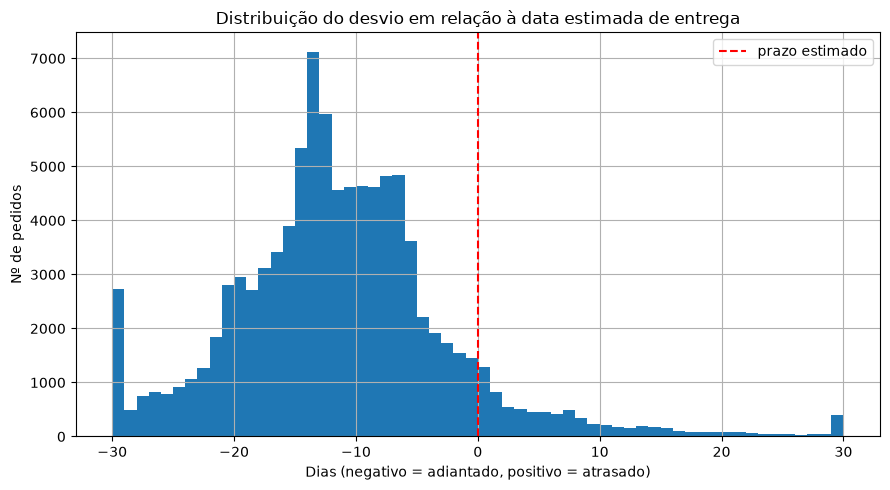

In [5]:
order_level = delivered.drop_duplicates("order_id")

on_time_rate = 1 - order_level["is_late"].mean()
avg_delivery = order_level["delivery_days"].mean()
late_orders = order_level[order_level["is_late"]]
avg_delay_when_late = late_orders["delay_days"].mean()

print(f"Tempo médio de entrega (compra -> cliente): {avg_delivery:.1f} dias")
print(f"Taxa de pedidos entregues no prazo: {on_time_rate*100:.1f}%")
print(f"Taxa de pedidos ATRASADOS: {(1-on_time_rate)*100:.1f}%  ({len(late_orders):,} pedidos)")
print(f"Atraso médio quando atrasado: {avg_delay_when_late:.1f} dias")

fig, ax = plt.subplots()
order_level["delay_days"].clip(-30, 30).hist(bins=60, ax=ax)
ax.axvline(0, color="red", linestyle="--", label="prazo estimado")
ax.set_title("Distribuição do desvio em relação à data estimada de entrega")
ax.set_xlabel("Dias (negativo = adiantado, positivo = atrasado)")
ax.set_ylabel("Nº de pedidos")
ax.legend()
plt.tight_layout()
plt.show()

### Tempo de entrega: histograma e boxplot

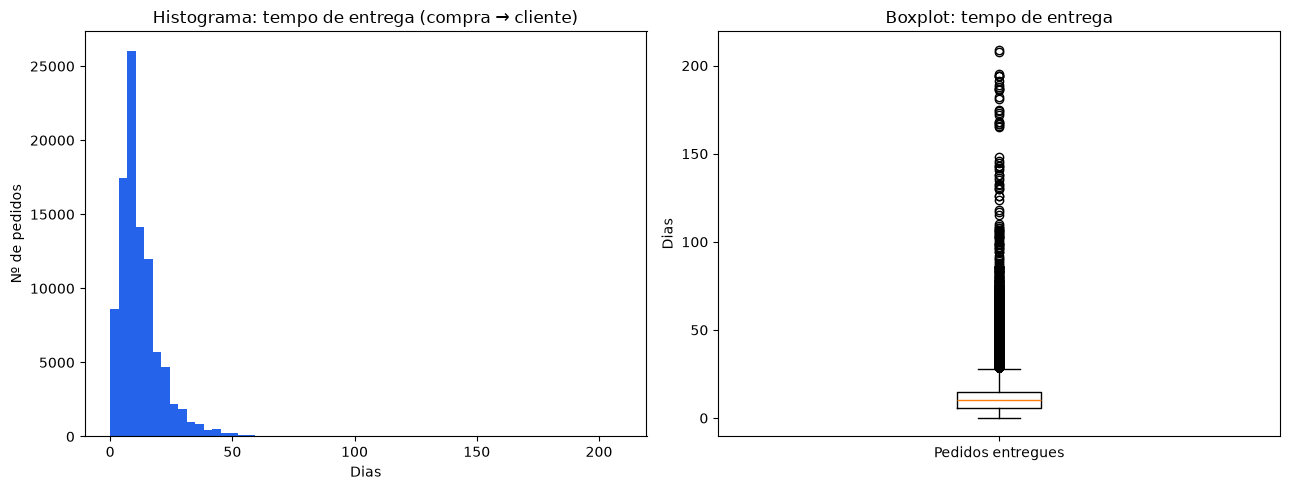

Estatísticas descritivas — tempo de entrega (dias):
count    96470.0
mean        12.1
std          9.6
min          0.0
25%          6.0
50%         10.0
75%         15.0
90%         23.0
95%         29.0
99%         46.0
max        209.0
Name: delivery_days, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order_level["delivery_days"].plot(kind="hist", bins=60, ax=axes[0], color="#2563eb")
axes[0].set_title("Histograma: tempo de entrega (compra → cliente)")
axes[0].set_xlabel("Dias")
axes[0].set_ylabel("Nº de pedidos")

axes[1].boxplot(order_level["delivery_days"].dropna(), showfliers=True)
axes[1].set_title("Boxplot: tempo de entrega")
axes[1].set_ylabel("Dias")
axes[1].set_xticklabels(["Pedidos entregues"])

plt.tight_layout()
plt.show()

desc_delivery = order_level["delivery_days"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1)
print("Estatísticas descritivas — tempo de entrega (dias):")
print(desc_delivery)

### Atraso em relação ao prazo estimado: boxplot

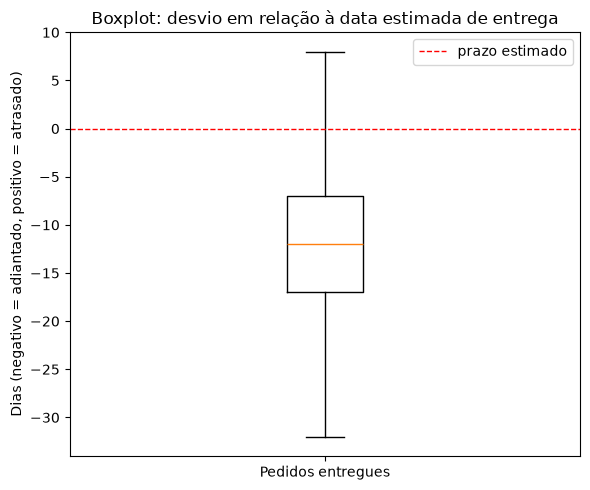

Estatísticas descritivas — atraso em dias (negativo = adiantado):
count    96470.0
mean       -11.9
std         10.2
min       -147.0
25%        -17.0
50%        -12.0
75%         -7.0
90%         -2.0
95%          3.0
99%         18.0
max        188.0
Name: delay_days, dtype: float64


In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot(order_level["delay_days"].dropna(), showfliers=False)
ax.axhline(0, color="red", linestyle="--", linewidth=1, label="prazo estimado")
ax.set_title("Boxplot: desvio em relação à data estimada de entrega")
ax.set_ylabel("Dias (negativo = adiantado, positivo = atrasado)")
ax.set_xticklabels(["Pedidos entregues"])
ax.legend()
plt.tight_layout()
plt.show()

desc_delay = order_level["delay_days"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1)
print("Estatísticas descritivas — atraso em dias (negativo = adiantado):")
print(desc_delay)

In [8]:
by_state = order_level.groupby("customer_state").agg(
    pedidos=("order_id", "count"),
    taxa_atraso=("is_late", "mean"),
    tempo_medio_entrega=("delivery_days", "mean"),
    desvio_padrao_entrega=("delivery_days", "std"),
).query("pedidos >= 30").sort_values("taxa_atraso", ascending=False)
by_state["taxa_atraso"] = (by_state["taxa_atraso"] * 100).round(1)
by_state["tempo_medio_entrega"] = by_state["tempo_medio_entrega"].round(1)
by_state["desvio_padrao_entrega"] = by_state["desvio_padrao_entrega"].round(1)
by_state["coef_variacao"] = (by_state["desvio_padrao_entrega"] / by_state["tempo_medio_entrega"]).round(2)

print("Top 10 estados com maior taxa de atraso (mín. 30 pedidos):")
by_state.head(10)

Top 10 estados com maior taxa de atraso (mín. 30 pedidos):


,pedidos,taxa_atraso,tempo_medio_entrega,desvio_padrao_entrega,coef_variacao
customer_state,,,,,
AL,397,21.4,24.0,11.5,0.48
MA,717,17.4,21.1,11.4,0.54
SE,335,15.2,21.0,16.8,0.80
PI,476,13.9,19.0,14.7,0.77
CE,1279,13.8,20.8,13.1,0.63
RR,41,12.2,29.0,27.8,0.96
BA,3256,12.2,18.9,11.7,0.62
RJ,12350,12.1,14.8,11.5,0.78
PA,946,11.2,23.3,13.2,0.57


## 5. Reviews e satisfação do cliente

              reviews     %
review_score               
1               11424  11.5
2                3151   3.2
3                8179   8.2
4               19142  19.3
5               57328  57.8

% de notas negativas (1-2): 14.7%
% de notas positivas (4-5): 77.1%
% de reviews com comentário escrito: 41.3%


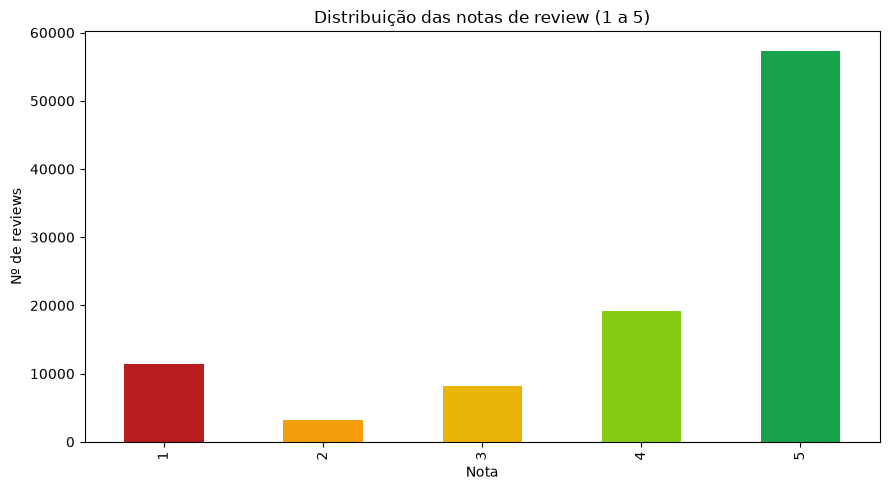

In [9]:
score_counts = reviews["review_score"].value_counts().sort_index()
score_pct = (score_counts / len(reviews) * 100).round(1)
print(pd.DataFrame({"reviews": score_counts, "%": score_pct}))

pct_negative = score_pct.loc[[1, 2]].sum()
pct_positive = score_pct.loc[[4, 5]].sum()
print(f"\n% de notas negativas (1-2): {pct_negative:.1f}%")
print(f"% de notas positivas (4-5): {pct_positive:.1f}%")

pct_with_comment = reviews["review_comment_message"].notna().mean() * 100
print(f"% de reviews com comentário escrito: {pct_with_comment:.1f}%")

fig, ax = plt.subplots()
score_counts.plot(kind="bar", ax=ax, color=["#b91c1c","#f59e0b","#eab308","#84cc16","#16a34a"])
ax.set_title("Distribuição das notas de review (1 a 5)")
ax.set_xlabel("Nota")
ax.set_ylabel("Nº de reviews")
plt.tight_layout()
plt.show()

In [10]:
from scipy.stats import spearmanr

orders_reviews = orders[["order_id", "order_status"]].merge(reviews, on="order_id", how="inner")
orders_reviews = orders_reviews.merge(
    order_level[["order_id", "is_late", "delay_days"]], on="order_id", how="inner"
)

# alguns pedidos "delivered" têm order_delivered_customer_date ausente (inconsistência conhecida
# do dataset Olist) -> delay_days fica NaN; removemos essas linhas antes de correlacionar
n_before = len(orders_reviews)
orders_reviews = orders_reviews.dropna(subset=["delay_days", "review_score"])
print(f"Linhas removidas por delay_days ausente: {n_before - len(orders_reviews)}")

score_on_time = orders_reviews.loc[~orders_reviews["is_late"], "review_score"].mean()
score_late = orders_reviews.loc[orders_reviews["is_late"], "review_score"].mean()

# review_score é ordinal (1-5), não contínua: Pearson assume distância igual entre categorias,
# premissa questionável aqui. Spearman é mais adequado porque não exige essa suposição —
# mede apenas se a relação é monotônica.
pearson_corr = orders_reviews["delay_days"].corr(orders_reviews["review_score"])
spearman_corr, spearman_pvalue = spearmanr(orders_reviews["delay_days"], orders_reviews["review_score"])

print(f"\nNota média quando entregue NO PRAZO: {score_on_time:.2f}")
print(f"Nota média quando entregue COM ATRASO: {score_late:.2f}")
print(f"\nCorrelação de Pearson  (atraso x nota): {pearson_corr:.3f}  — assume nota como intervalar/contínua")
print(f"Correlação de Spearman (atraso x nota): {spearman_corr:.3f}  — correta para nota ordinal (baseada em ranks)")
print(f"p-valor da correlação de Spearman: {spearman_pvalue:.2e}  (estatisticamente significativa)")

Linhas removidas por delay_days ausente: 8

Nota média quando entregue NO PRAZO: 4.29
Nota média quando entregue COM ATRASO: 2.27

Correlação de Pearson  (atraso x nota): -0.267  — assume nota como intervalar/contínua
Correlação de Spearman (atraso x nota): -0.176  — correta para nota ordinal (baseada em ranks)
p-valor da correlação de Spearman: 0.00e+00  (estatisticamente significativa)


### Relação visual entre atraso e nota de review

                        pedidos  nota_media
delay_bucket                               
No prazo/adiantado        89939        4.29
Atraso leve (1-3d)         1856        3.29
Atraso moderado (4-7d)     1756        2.10
Atraso severo (8+d)        2797        1.70


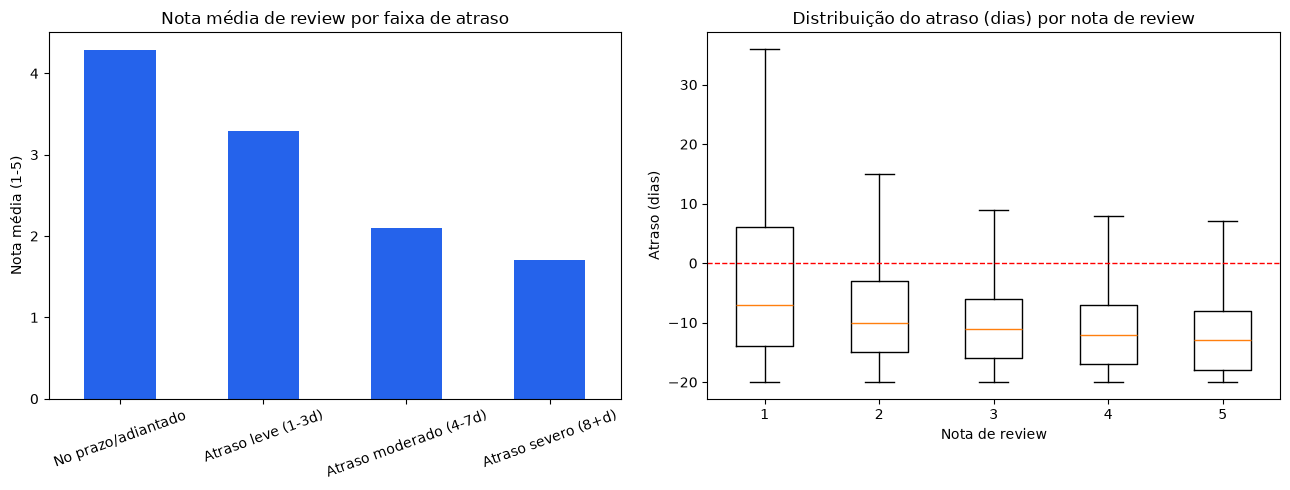

In [11]:
bins = [-100, 0, 3, 7, 1000]
labels = ["No prazo/adiantado", "Atraso leve (1-3d)", "Atraso moderado (4-7d)", "Atraso severo (8+d)"]
orders_reviews["delay_bucket"] = pd.cut(orders_reviews["delay_days"], bins=bins, labels=labels)

bucket_summary = orders_reviews.groupby("delay_bucket", observed=True).agg(
    pedidos=("order_id", "count"),
    nota_media=("review_score", "mean"),
).round(2)
print(bucket_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bucket_summary["nota_media"].plot(kind="bar", ax=axes[0], color="#2563eb")
axes[0].set_title("Nota média de review por faixa de atraso")
axes[0].set_ylabel("Nota média (1-5)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

box_data = [orders_reviews.loc[orders_reviews["review_score"] == s, "delay_days"].clip(-20, 40) for s in range(1, 6)]
axes[1].boxplot(box_data, tick_labels=[1, 2, 3, 4, 5], showfliers=False)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_title("Distribuição do atraso (dias) por nota de review")
axes[1].set_xlabel("Nota de review")
axes[1].set_ylabel("Atraso (dias)")

plt.tight_layout()
plt.show()

### Boxplot dedicado: atraso (dias) por categoria de nota (1-5)

Estatísticas de atraso (dias) por nota de review:
              pedidos    Q1  mediana   Q3  média
review_score                                    
1              9405.0 -14.0     -7.0  6.0   -4.0
2              2941.0 -15.0    -10.0 -3.0   -8.6
3              7961.0 -16.0    -11.0 -6.0  -10.8
4             18987.0 -17.0    -12.0 -7.0  -12.4
5             57059.0 -18.0    -13.0 -8.0  -13.4


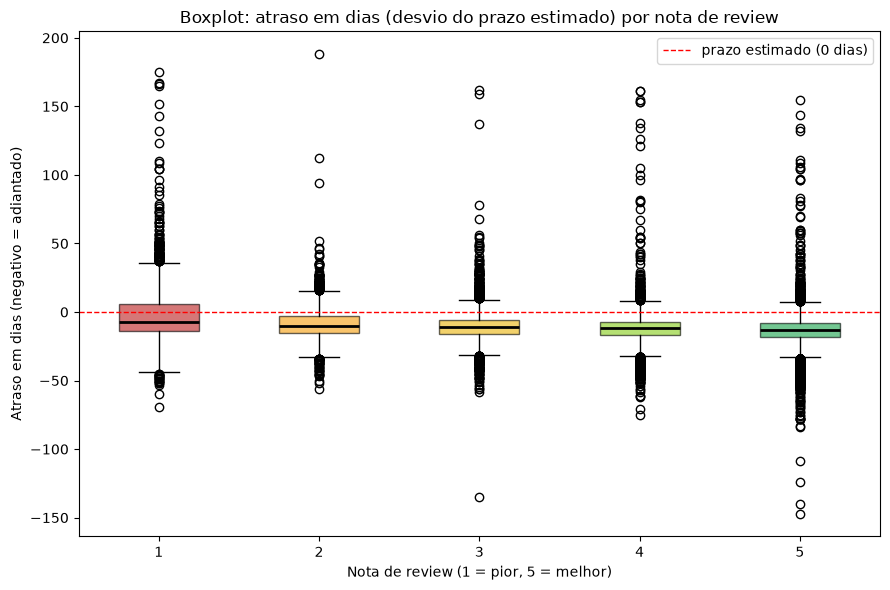

In [12]:
delay_by_score_stats = orders_reviews.groupby("review_score")["delay_days"].describe(
    percentiles=[.25, .5, .75]
)[["count", "25%", "50%", "75%", "mean"]].round(1)
delay_by_score_stats.columns = ["pedidos", "Q1", "mediana", "Q3", "média"]
print("Estatísticas de atraso (dias) por nota de review:")
print(delay_by_score_stats)

fig, ax = plt.subplots(figsize=(9, 6))
box_data_full = [orders_reviews.loc[orders_reviews["review_score"] == s, "delay_days"] for s in range(1, 6)]
bp = ax.boxplot(
    box_data_full, tick_labels=[1, 2, 3, 4, 5], showfliers=True,
    patch_artist=True, medianprops=dict(color="black", linewidth=2)
)
colors = ["#b91c1c", "#f59e0b", "#eab308", "#84cc16", "#16a34a"]
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax.axhline(0, color="red", linestyle="--", linewidth=1, label="prazo estimado (0 dias)")
ax.set_title("Boxplot: atraso em dias (desvio do prazo estimado) por nota de review")
ax.set_xlabel("Nota de review (1 = pior, 5 = melhor)")
ax.set_ylabel("Atraso em dias (negativo = adiantado)")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
items_reviews = master[["order_id", "product_category_name_english"]].merge(
    reviews[["order_id", "review_score"]], on="order_id", how="inner"
)

cat_scores = items_reviews.groupby("product_category_name_english").agg(
    itens=("review_score", "count"),
    nota_media=("review_score", "mean"),
).query("itens >= 100").sort_values("nota_media")
cat_scores["nota_media"] = cat_scores["nota_media"].round(2)

print("10 categorias com PIOR nota média (mín. 100 itens avaliados):")
print(cat_scores.head(10))
print("\n10 categorias com MELHOR nota média (mín. 100 itens avaliados):")
print(cat_scores.sort_values("nota_media", ascending=False).head(10))

10 categorias com PIOR nota média (mín. 100 itens avaliados):
                               itens  nota_media
product_category_name_english                   
office_furniture                1687        3.49
fashion_male_clothing            131        3.64
fixed_telephony                  262        3.68
audio                            361        3.83
home_confort                     435        3.83
construction_tools_safety        193        3.84
bed_bath_table                 11137        3.90
furniture_decor                 8331        3.90
furniture_living_room            502        3.90
computers_accessories           7849        3.93

10 categorias com MELHOR nota média (mín. 100 itens avaliados):
                               itens  nota_media
product_category_name_english                   
books_general_interest           549        4.45
books_technical                  266        4.37
food_drink                       279        4.32
luggage_accessories             1088    

In [14]:
import re
from collections import Counter

STOPWORDS_PT = set("""
a o e é de da do das dos em um uma para com não que se os as na no nas nos por
mais muito foi ser está esta isso essa esse mas ja já ainda tão ate até sem
produto pedido compra comprei recebi veio chegou""".split())

negative_comments = reviews.loc[
    (reviews["review_score"] <= 2) & reviews["review_comment_message"].notna(),
    "review_comment_message"
]

words = Counter()
for text in negative_comments.str.lower():
    tokens = re.findall(r"[a-záàâãéèêíïóôõöúçñ]{4,}", text)
    words.update(t for t in tokens if t not in STOPWORDS_PT)

print(f"Total de reviews negativos (nota 1-2) com comentário: {len(negative_comments):,}")
print("\nTermos mais frequentes em reviews negativos:")
for word, count in words.most_common(20):
    print(f"  {word:15s} {count}")

Total de reviews negativos (nota 1-2) com comentário: 10,890

Termos mais frequentes em reviews negativos:
  entrega         1412
  entregue        1329
  estou           961
  prazo           916
  loja            775
  agora           689
  como            684
  minha           615
  apenas          540
  lannister       540
  pois            528
  quero           519
  nada            517
  produtos        515
  site            513
  dois            501
  mesmo           472
  contato         467
  dias            438
  qualidade       436


## 6. Pagamentos

In [15]:
pay_type = payments["payment_type"].value_counts(normalize=True).mul(100).round(1)
print("Distribuição por tipo de pagamento (%):")
print(pay_type)

installments_dist = payments.loc[payments["payment_type"] == "credit_card", "payment_installments"].value_counts(normalize=True).sort_index().mul(100).round(1)
print("\n% de compras no cartão por nº de parcelas (top 10):")
print(installments_dist.head(10))

avg_ticket_by_type = payments.groupby("payment_type")["payment_value"].mean().round(2).sort_values(ascending=False)
print("\nTicket médio por tipo de pagamento (R$):")
print(avg_ticket_by_type)

Distribuição por tipo de pagamento (%):
payment_type
credit_card    73.9
boleto         19.0
voucher         5.6
debit_card      1.5
not_defined     0.0
Name: proportion, dtype: float64

% de compras no cartão por nº de parcelas (top 10):
payment_installments
0     0.0
1    33.1
2    16.2
3    13.6
4     9.2
5     6.8
6     5.1
7     2.1
8     5.6
9     0.8
Name: proportion, dtype: float64

Ticket médio por tipo de pagamento (R$):
payment_type
credit_card    163.32
boleto         145.03
debit_card     142.57
voucher         65.70
not_defined      0.00
Name: payment_value, dtype: float64


## 7. Produtos e categorias

In [16]:
cat_summary = master.groupby("product_category_name_english").agg(
    itens_vendidos=("order_item_id", "count"),
    receita=("price", "sum"),
    preco_medio=("price", "mean"),
    frete_medio=("freight_value", "mean"),
).sort_values("receita", ascending=False)
cat_summary["receita"] = cat_summary["receita"].round(0)
cat_summary["preco_medio"] = cat_summary["preco_medio"].round(2)
cat_summary["frete_medio"] = cat_summary["frete_medio"].round(2)
cat_summary["frete_pct_preco"] = (cat_summary["frete_medio"] / cat_summary["preco_medio"] * 100).round(1)

print("Top 10 categorias por receita:")
print(cat_summary.head(10)[["itens_vendidos", "receita", "preco_medio"]])

print("\nTop 10 categorias com MAIOR peso de frete sobre o preço (mín. 100 itens):")
print(cat_summary.query("itens_vendidos >= 100").sort_values("frete_pct_preco", ascending=False).head(10)[["itens_vendidos", "preco_medio", "frete_medio", "frete_pct_preco"]])

Top 10 categorias por receita:


                               itens_vendidos    receita  preco_medio
product_category_name_english                                        
health_beauty                            9670  1258681.0       130.16
watches_gifts                            5991  1205006.0       201.14
bed_bath_table                          11115  1036989.0        93.30
sports_leisure                           8641   988049.0       114.34
computers_accessories                    7827   911954.0       116.51
furniture_decor                          8334   729762.0        87.56
cool_stuff                               3796   635291.0       167.36
housewares                               6964   632249.0        90.79
auto                                     4235   592720.0       139.96
garden_tools                             4347   485256.0       111.63

Top 10 categorias com MAIOR peso de frete sobre o preço (mín. 100 itens):
                                         itens_vendidos  preco_medio  frete_medio  fr

## 8. Vendedores (sellers)

In [17]:
seller_revenue = master.groupby("seller_id")["price"].sum().sort_values(ascending=False)
n_sellers = len(seller_revenue)
top10pct_n = max(1, int(n_sellers * 0.10))
share_top10pct = seller_revenue.head(top10pct_n).sum() / seller_revenue.sum() * 100

print(f"Total de vendedores ativos: {n_sellers:,}")
print(f"Os {top10pct_n:,} maiores vendedores (top 10%) concentram {share_top10pct:.1f}% da receita total")

seller_perf = delivered.groupby("seller_id").agg(
    pedidos=("order_id", "nunique"),
    taxa_atraso=("is_late", "mean"),
).query("pedidos >= 20").sort_values("taxa_atraso", ascending=False)
seller_perf["taxa_atraso"] = (seller_perf["taxa_atraso"] * 100).round(1)

print(f"\nVendedores com >=20 pedidos entregues: {len(seller_perf):,}")
print("10 piores vendedores por taxa de atraso:")
print(seller_perf.head(10))

Total de vendedores ativos: 3,095
Os 309 maiores vendedores (top 10%) concentram 67.5% da receita total

Vendedores com >=20 pedidos entregues: 804
10 piores vendedores por taxa de atraso:
                                  pedidos  taxa_atraso
seller_id                                             
2709af9587499e95e803a6498a5a56e9       25         50.0
54965bbe3e4f07ae045b90b0b8541f52       73         32.1
821fb029fc6e495ca4f08a35d51e53a5       24         32.0
ede0c03645598cdfc63ca8237acbe73d       43         31.9
ad781527c93d00d89a11eecd9dcad7c1       38         31.6
7f152321c60a266edc53af1925ef96c1       20         30.0
2a1348e9addc1af5aaa619b1a3679d6b       48         29.4
f76a3b1349b6df1ee875d1f3fa4340f0       24         29.2
054694fa03fe82cec4b7551487331d74       20         28.6
835f0f7810c76831d6c7d24c7a646d4d       42         27.1


## 9. Geografia: cliente x vendedor em estados diferentes

In [18]:
cust_top_states = customers["customer_state"].value_counts(normalize=True).mul(100).round(1).head(10)
print("Top 10 estados por volume de clientes (%):")
print(cust_top_states)

geo = delivered.copy()
geo["same_state"] = geo["customer_state"] == geo["seller_state"]

cross_state_summary = geo.groupby("same_state").agg(
    pedidos=("order_id", "nunique"),
    tempo_medio_entrega=("delivery_days", "mean"),
    taxa_atraso=("is_late", "mean"),
)
cross_state_summary.index = cross_state_summary.index.map({True: "mesmo_estado", False: "estados_diferentes"})
cross_state_summary["tempo_medio_entrega"] = cross_state_summary["tempo_medio_entrega"].round(1)
cross_state_summary["taxa_atraso"] = (cross_state_summary["taxa_atraso"] * 100).round(1)

print("\nEntrega dentro do mesmo estado vs. entre estados diferentes:")
print(cross_state_summary)

Top 10 estados por volume de clientes (%):
customer_state
SP    42.0
RJ    12.9
MG    11.7
RS     5.5
PR     5.1
SC     3.7
BA     3.4
DF     2.2
ES     2.0
GO     2.0
Name: proportion, dtype: float64

Entrega dentro do mesmo estado vs. entre estados diferentes:
                    pedidos  tempo_medio_entrega  taxa_atraso
same_state                                                   
estados_diferentes    61898                 14.6          7.8
mesmo_estado          34827                  7.5          4.4


## 10. O que mais afeta a nota de review? (análise multivariada exploratória)

Até aqui olhamos o atraso isoladamente. Nesta seção comparamos, lado a lado, a força de associação
entre a nota de review e várias outras variáveis candidatas — preço, frete, nº de itens, peso do
produto, qualidade do anúncio (fotos/descrição), parcelamento e estado (mesmo estado vs. interestadual).
Como a nota é ordinal, usamos **Spearman** para todas as comparações (consistente com a decisão tomada
na Seção 5), o que também torna os coeficientes diretamente comparáveis entre si.

Correlação de Spearman de cada variável com a nota de review (ordenado por força):
                     spearman        p_valor      n
delivery_days          -0.234   0.000000e+00  96353
delay_days             -0.176   0.000000e+00  96353
n_items                -0.108  6.239873e-246  96353
freight_total          -0.089  5.988105e-167  96353
same_state              0.060   1.516591e-77  96353
payment_value_total    -0.040   1.115070e-34  96352
freight_pct_price      -0.031   2.256676e-21  96353
price_total            -0.029   5.760087e-20  96353
max_installments       -0.021   1.057876e-10  96352
avg_weight_g           -0.014   8.064790e-06  96337
avg_desc_len            0.012   1.477267e-04  95021
avg_photos              0.009   4.271407e-03  95021


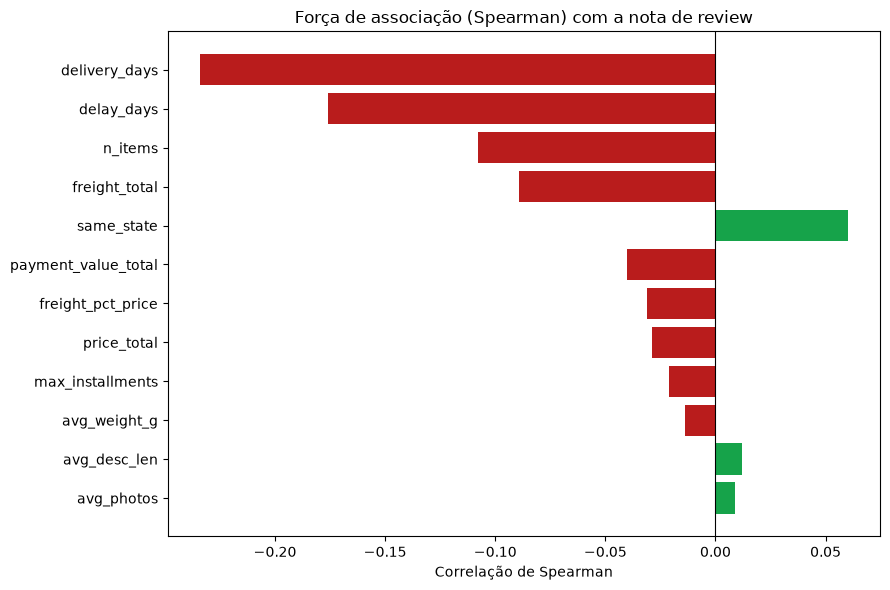

In [19]:
order_agg = master.groupby("order_id").agg(
    price_total=("price", "sum"),
    freight_total=("freight_value", "sum"),
    n_items=("order_item_id", "count"),
    avg_weight_g=("product_weight_g", "mean"),
    avg_photos=("product_photos_qty", "mean"),
    avg_desc_len=("product_description_lenght", "mean"),
).reset_index()
order_agg["freight_pct_price"] = order_agg["freight_total"] / order_agg["price_total"] * 100

payments_agg = payments.groupby("order_id").agg(
    payment_value_total=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
).reset_index()

analysis_df = (
    orders_reviews[["order_id", "review_score", "delay_days"]]
    .merge(order_level[["order_id", "delivery_days", "customer_state", "seller_state"]], on="order_id", how="left")
    .merge(order_agg, on="order_id", how="left")
    .merge(payments_agg, on="order_id", how="left")
)
analysis_df["same_state"] = (analysis_df["customer_state"] == analysis_df["seller_state"]).astype(int)

candidate_vars = [
    "delay_days", "delivery_days", "price_total", "freight_total", "freight_pct_price",
    "n_items", "avg_weight_g", "avg_photos", "avg_desc_len",
    "payment_value_total", "max_installments", "same_state",
]

spearman_results = {}
for var in candidate_vars:
    sub = analysis_df[[var, "review_score"]].dropna()
    corr, pval = spearmanr(sub[var], sub["review_score"])
    spearman_results[var] = {"spearman": corr, "p_valor": pval, "n": len(sub)}

spearman_table = pd.DataFrame(spearman_results).T.sort_values("spearman", key=lambda s: s.abs(), ascending=False)
spearman_table["spearman"] = spearman_table["spearman"].round(3)
spearman_table["n"] = spearman_table["n"].astype(int)
print("Correlação de Spearman de cada variável com a nota de review (ordenado por força):")
print(spearman_table)

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#b91c1c" if v < 0 else "#16a34a" for v in spearman_table["spearman"]]
ax.barh(spearman_table.index[::-1], spearman_table["spearman"][::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Força de associação (Spearman) com a nota de review")
ax.set_xlabel("Correlação de Spearman")
plt.tight_layout()
plt.show()

In [20]:
# variável categórica (não entra na tabela de Spearman): tipo de pagamento
score_by_paytype = (
    payments[["order_id", "payment_type"]]
    .drop_duplicates("order_id")
    .merge(orders_reviews[["order_id", "review_score"]], on="order_id", how="inner")
    .groupby("payment_type")
    .agg(pedidos=("review_score", "count"), nota_media=("review_score", "mean"))
    .query("pedidos >= 100")
    .sort_values("nota_media", ascending=False)
)
score_by_paytype["nota_media"] = score_by_paytype["nota_media"].round(2)
print("Nota média por tipo de pagamento:")
print(score_by_paytype)

Nota média por tipo de pagamento:
              pedidos  nota_media
payment_type                     
debit_card       1484        4.24
boleto          19179        4.16
credit_card     73110        4.16
voucher          2579        4.12


## 11. Séries temporais: vendas e atrasos ao longo dos meses

Agregamos por mês de compra (`order_purchase_timestamp`) para visualizar a evolução de receita,
volume de pedidos e atrasos ao longo do tempo. **Atenção:** o primeiro mês (set/2016) e o último mês
do dataset têm volume muito baixo/incompleto (início da operação e corte de coleta de dados,
respectivamente) — isso aparece como quedas abruptas nas pontas dos gráficos e não deve ser
interpretado como sazonalidade real.

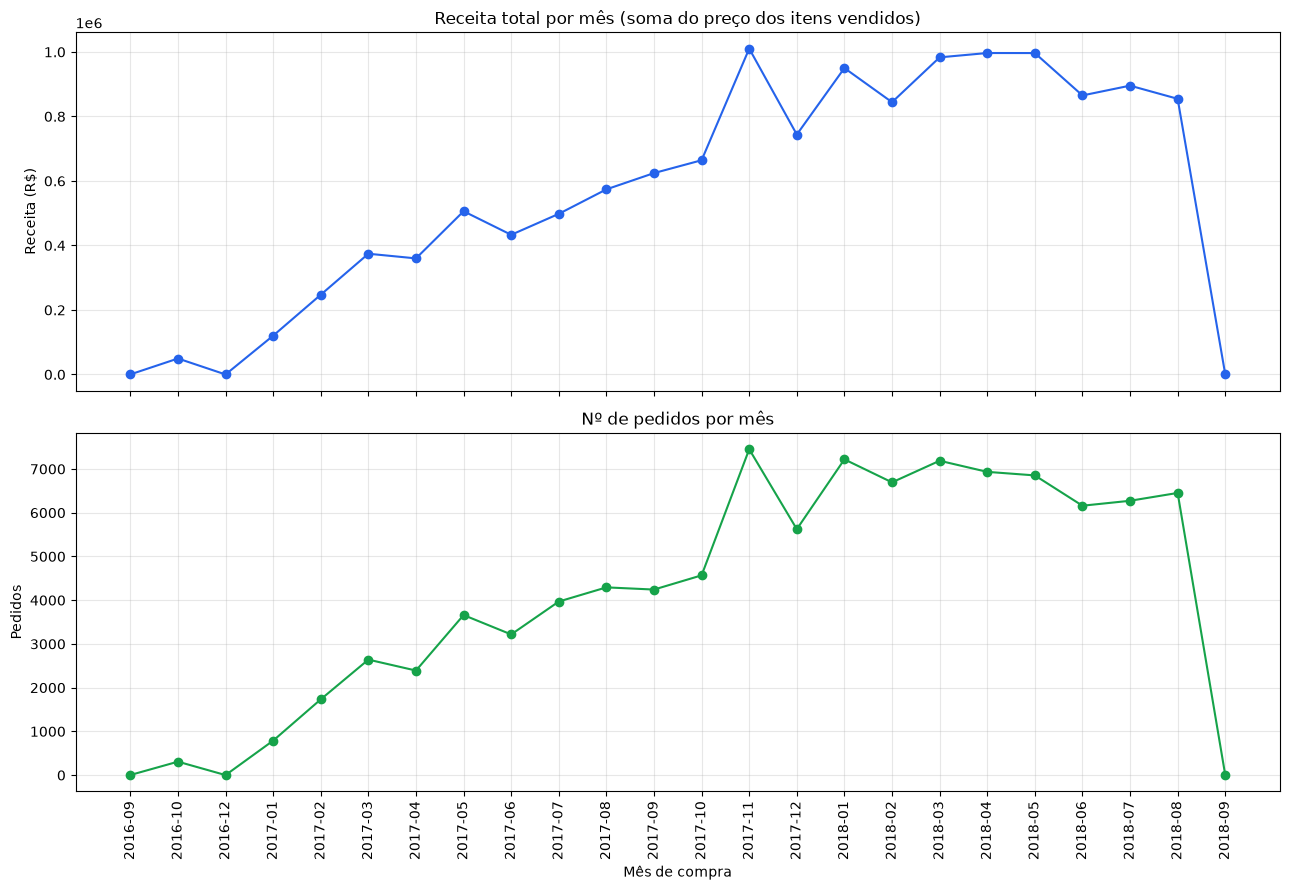

Receita e pedidos por mês:
order_month    receita  pedidos
    2016-09     267.36        3
    2016-10   49507.66      308
    2016-12      10.90        1
    2017-01  120312.87      789
    2017-02  247303.02     1733
    2017-03  374344.30     2641
    2017-04  359927.23     2391
    2017-05  506071.14     3660
    2017-06  433038.60     3217
    2017-07  498031.48     3969
    2017-08  573971.68     4293
    2017-09  624401.69     4243
    2017-10  664219.43     4568
    2017-11 1010271.37     7451
    2017-12  743914.17     5624
    2018-01  950030.36     7220
    2018-02  844178.71     6694
    2018-03  983213.44     7188
    2018-04  996647.75     6934
    2018-05  996517.68     6853
    2018-06  865124.31     6160
    2018-07  895507.22     6273
    2018-08  854686.33     6452
    2018-09     145.00        1


In [21]:
master_month = master.copy()
master_month["order_month"] = master_month["order_purchase_timestamp"].dt.to_period("M").astype(str)

monthly_sales = master_month.groupby("order_month").agg(
    receita=("price", "sum"),
    pedidos=("order_id", "nunique"),
).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

axes[0].plot(monthly_sales["order_month"], monthly_sales["receita"], marker="o", color="#2563eb")
axes[0].set_title("Receita total por mês (soma do preço dos itens vendidos)")
axes[0].set_ylabel("Receita (R$)")
axes[0].grid(alpha=0.3)

axes[1].plot(monthly_sales["order_month"], monthly_sales["pedidos"], marker="o", color="#16a34a")
axes[1].set_title("Nº de pedidos por mês")
axes[1].set_ylabel("Pedidos")
axes[1].set_xlabel("Mês de compra")
axes[1].tick_params(axis="x", rotation=90)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Receita e pedidos por mês:")
print(monthly_sales.to_string(index=False))

### Pedidos atrasados ao longo dos meses

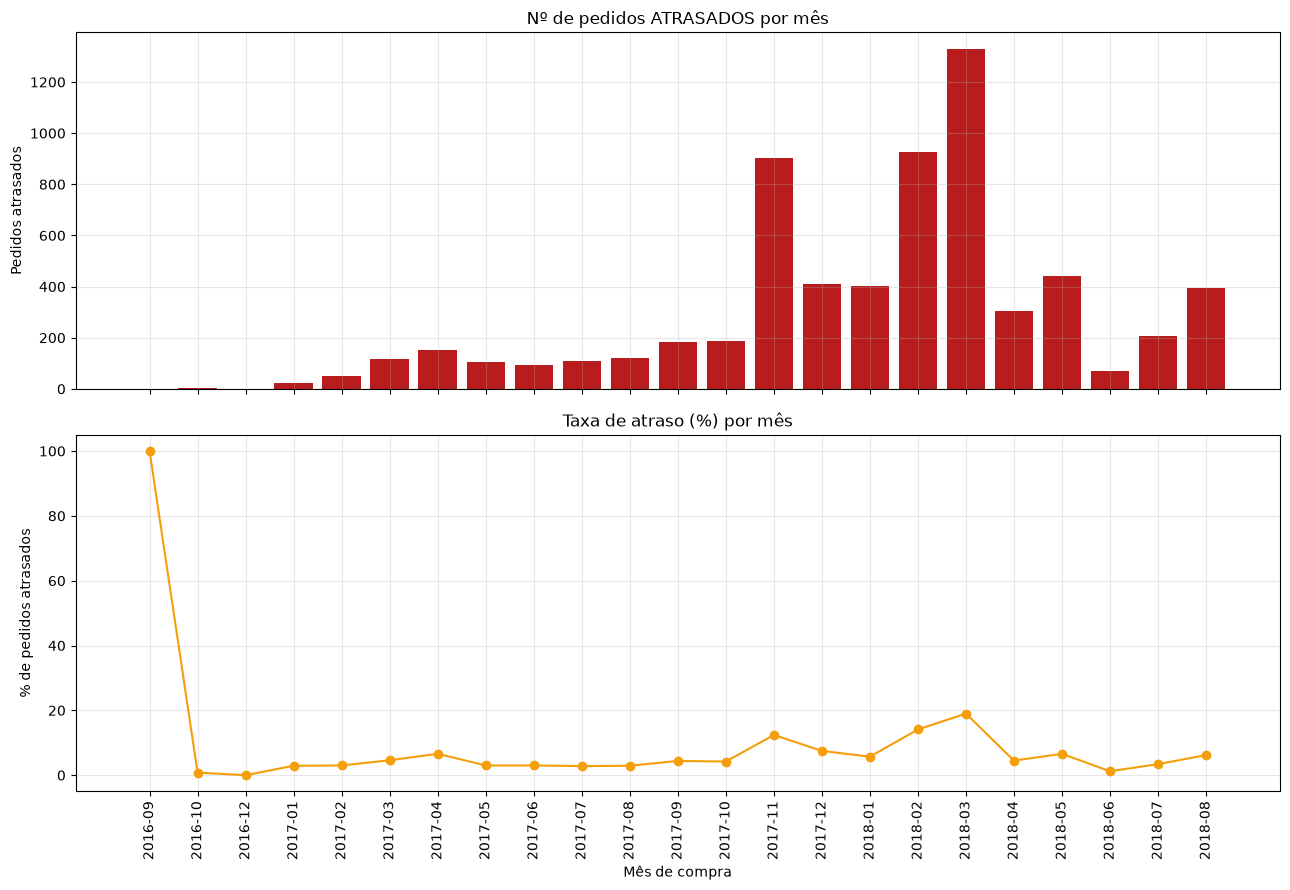

Pedidos atrasados e taxa de atraso por mês:
order_month  pedidos  atrasados  taxa_atraso
    2016-09        1          1        100.0
    2016-10      265          2          0.8
    2016-12        1          0          0.0
    2017-01      750         22          2.9
    2017-02     1653         49          3.0
    2017-03     2546        116          4.6
    2017-04     2303        151          6.6
    2017-05     3546        106          3.0
    2017-06     3135         95          3.0
    2017-07     3872        108          2.8
    2017-08     4193        122          2.9
    2017-09     4150        182          4.4
    2017-10     4478        187          4.2
    2017-11     7289        904         12.4
    2017-12     5513        411          7.5
    2018-01     7069        403          5.7
    2018-02     6555        926         14.1
    2018-03     7003       1328         19.0
    2018-04     6798        306          4.5
    2018-05     6749        443          6.6
    2018-06

In [22]:
order_level_month = order_level.copy()
order_level_month["order_month"] = order_level_month["order_purchase_timestamp"].dt.to_period("M").astype(str)

monthly_delay = order_level_month.groupby("order_month").agg(
    pedidos=("order_id", "count"),
    atrasados=("is_late", "sum"),
    taxa_atraso=("is_late", "mean"),
).reset_index()
monthly_delay["taxa_atraso"] = (monthly_delay["taxa_atraso"] * 100).round(1)

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

axes[0].bar(monthly_delay["order_month"], monthly_delay["atrasados"], color="#b91c1c")
axes[0].set_title("Nº de pedidos ATRASADOS por mês")
axes[0].set_ylabel("Pedidos atrasados")
axes[0].grid(alpha=0.3)

axes[1].plot(monthly_delay["order_month"], monthly_delay["taxa_atraso"], marker="o", color="#f59e0b")
axes[1].set_title("Taxa de atraso (%) por mês")
axes[1].set_ylabel("% de pedidos atrasados")
axes[1].set_xlabel("Mês de compra")
axes[1].tick_params(axis="x", rotation=90)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Pedidos atrasados e taxa de atraso por mês:")
print(monthly_delay.to_string(index=False))

## 12. Resumo consolidado dos números-chave

In [23]:
print("=== RESUMO EXECUTIVO DOS NÚMEROS ===\n")
print(f"Pedidos no dataset: {len(orders):,}  |  Período: {orders['order_purchase_timestamp'].min().date()} a {orders['order_purchase_timestamp'].max().date()}")
print(f"Taxa de cancelados/indisponíveis: {(status_pct.get('canceled',0)+status_pct.get('unavailable',0)):.1f}%")
print()
print(f"Tempo médio de entrega: {avg_delivery:.1f} dias")
print(f"Taxa de pedidos atrasados: {(1-on_time_rate)*100:.1f}%  |  atraso médio quando atrasa: {avg_delay_when_late:.1f} dias")
print(f"Nota média no prazo: {score_on_time:.2f}  vs  nota média atrasado: {score_late:.2f}")
print(f"Correlação atraso x nota — Pearson: {pearson_corr:.2f}  |  Spearman (ordinal, mais adequada): {spearman_corr:.2f}")
print()
print(f"% reviews negativos (1-2): {pct_negative:.1f}%  |  % reviews com comentário: {pct_with_comment:.1f}%")
print(f"Categoria com pior nota média: {cat_scores.index[0]} ({cat_scores.iloc[0]['nota_media']})")
print()
print(f"% pagamento em cartão de crédito: {pay_type.get('credit_card',0):.1f}%")
print(f"Concentração: top 10% dos vendedores ({top10pct_n}) geram {share_top10pct:.1f}% da receita")
print(f"Entregas entre estados diferentes: {cross_state_summary.loc['estados_diferentes','taxa_atraso']}% atraso vs {cross_state_summary.loc['mesmo_estado','taxa_atraso']}% no mesmo estado")

=== RESUMO EXECUTIVO DOS NÚMEROS ===

Pedidos no dataset: 99,441  |  Período: 2016-09-04 a 2018-10-17
Taxa de cancelados/indisponíveis: 1.2%

Tempo médio de entrega: 12.1 dias
Taxa de pedidos atrasados: 6.8%  |  atraso médio quando atrasa: 10.6 dias
Nota média no prazo: 4.29  vs  nota média atrasado: 2.27
Correlação atraso x nota — Pearson: -0.27  |  Spearman (ordinal, mais adequada): -0.18

% reviews negativos (1-2): 14.7%  |  % reviews com comentário: 41.3%
Categoria com pior nota média: office_furniture (3.49)

% pagamento em cartão de crédito: 73.9%
Concentração: top 10% dos vendedores (309) geram 67.5% da receita
Entregas entre estados diferentes: 7.8% atraso vs 4.4% no mesmo estado
